# P4.03 — Which regions are likely to worsen further? A validated regional outlook

**Question:** RQ10.2. The national forecast (p4_01) and the simulator (p4_02) say how affordability may move for the
median municipality; this notebook asks *where* it is likely to move more or less.

**What can be validated.** A municipality has nine annual points (2016 to 2024) and a noisy published level (the 12-month
median price rests on few sales; year-on-year growth has a lag-1 autocorrelation of -0.3 to -0.6). ETS or ARIMA per
municipality cannot be tested on that, so the methods are straight-line trends of growing complexity on the log of
price-to-income (`analysis/regional_forecast.py`): **naive** (no change), **national drift**, **national trend**,
**own trend**, trend of the municipality's **NUTS 3 region**, of its **coast x density class**, and the own trend **shrunk**
toward the region's by empirical Bayes. No machine learning: a more complex model has to beat these first.

**Validation:** rolling origin. At each origin from 2019 to 2023 every method sees only years up to it and forecasts one and
two years ahead; all methods are scored on the same municipalities. Scores: RMSE (log points), and how well the predicted
change ranks the actual change (Spearman, and the share of the predicted top fifth that is in the actual top fifth; chance is
20%), for municipalities and aggregated to the 24 NUTS 3 regions and the six classes. **Selection rule, fixed before
looking:** lowest mean municipal RMSE over both horizons; a tie within 1% goes to the simpler method. Intervals are
empirical quantiles of the errors from other origins, checked by leaving each origin out.

**What the outlook is, and is not.** Because the common swing (2023's jump, the 2025 price surge) is not predictable from
municipal history and the simulator already carries the national path, the outlook is expressed **relative to the median
municipality**. It ranks places; it does not give their level.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import regional_forecast as R
from pthousing.config import TABLES
from pthousing.viz import charts, dashboard, maps, style

style.apply_style()
panel = dashboard.load_panel()
y, groups = R.history(panel)
print(f"{len(y)} mainland municipalities, {y.columns.min()} to {y.columns.max()}")
print("with a value per year:", y.notna().sum().to_dict())
print("regions:", groups["region"].nunique(), "| classes:", groups["segment"].nunique())

278 mainland municipalities, 2016 to 2024
with a value per year: {2016: 271, 2017: 272, 2018: 272, 2019: 259, 2020: 257, 2021: 267, 2022: 270, 2023: 268, 2024: 273}
regions: 24 | classes: 6


## Step 1 — Rolling-origin validation
Municipal scores first. `rmse_vs_naive` is the method's RMSE over the naive forecast's (below 1 = better).

In [2]:
bt = R.backtest(y, groups)
print(bt.groupby(["origin", "h"])["muni_code"].nunique().unstack())
muni_acc = R.accuracy(bt)
naive = muni_acc[muni_acc["method"] == "naive"].set_index("h")["rmse"]
muni_acc["rmse_vs_naive"] = muni_acc["rmse"] / muni_acc["h"].map(naive)
muni_acc.round(3)

h           1      2
origin              
2019    257.0  267.0
2020    267.0  270.0
2021    270.0  268.0
2022    268.0  272.0
2023    272.0    NaN


,method,h,n,rmse,mae,bias,spearman,top_precision,rmse_vs_naive
0,naive,1,266.80,0.154,0.110,-0.023,NaN,0.166,1.000
1,naive,2,269.25,0.170,0.129,-0.037,NaN,0.140,1.000
2,national_drift,1,266.80,0.153,0.106,0.005,-0.086,0.232,0.992
3,national_drift,2,269.25,0.168,0.119,0.019,-0.011,0.130,0.990
4,national_trend,1,266.80,0.165,0.125,0.008,0.205,0.479,1.071
5,national_trend,2,269.25,0.188,0.143,0.016,0.063,0.335,1.107
6,own_trend,1,266.80,0.181,0.114,0.001,0.210,0.252,1.170
7,own_trend,2,269.25,0.238,0.149,0.009,0.133,0.205,1.403
8,region_trend,1,266.80,0.141,0.102,0.001,0.395,0.444,0.914
9,region_trend,2,269.25,0.163,0.119,0.009,0.378,0.391,0.959


### The same forecasts aggregated to regions and classes
For a group, the predicted and the actual change are the median over its municipalities. `rmse_relative` removes the
cross-group mean first: it scores *which groups move more than the others*, not the common swing.

In [3]:
level_acc = {"municipality": muni_acc}
for name, by in (("NUTS 3 region", "region"), ("coast x density class", "segment")):
    level_acc[name] = R.group_accuracy(R.group_backtest(bt, groups, by))
table = (
    pd.concat(level_acc, names=["level"])
    .reset_index(level=0)
    .drop(columns="level_1", errors="ignore")
)
style.save_table(table.round(4), "p4", "regional_accuracy")
pivot = table.pivot_table(
    index=["level", "method"], columns="h", values=["rmse", "spearman", "top_precision"]
)
pivot.round(3)

rmse        spearman         \
h                                         1      2        1      2   
level                 method                                         
NUTS 3 region         naive           0.059  0.090      NaN    NaN   
                      national_drift  0.055  0.081   -0.273 -0.338   
                      national_trend  0.108  0.124   -0.425 -0.511   
                      own_trend       0.063  0.090    0.121  0.292   
                      region_trend    0.071  0.096    0.132  0.296   
                      segment_trend   0.067  0.070    0.159  0.500   
                      shrunk_trend    0.064  0.091    0.126  0.333   
coast x density class naive           0.052  0.098      NaN    NaN   
                      national_drift  0.037  0.060   -0.655 -0.278   
                      national_trend  0.108  0.125   -0.703 -0.857   
                      own_trend       0.036  0.046    0.680  0.886   
                      region_trend    0.036  0.045    0.383  0.786   
                      segment_trend   0.037  0.048    0.726  0.757   
                      shrunk_trend    0.035  0.042    0.497  0.829   
municipality          naive           0.154  0.170      NaN    NaN   
                      national_drift  0.153  0.168   -0.086 -0.011   
                      national_trend  0.165  0.188    0.205  0.063   
                      own_trend       0.181  0.238    0.210  0.133   
                      region_trend    0.141  0.163    0.395  0.378   
                      segment_trend   0.141  0.156    0.409  0.430   
                      shrunk_trend    0.155  0.194    0.347  0.271   

                                     top_precision         
h                                                1      2  
level                 method                               
NUTS 3 region         naive                  0.280  0.250  
                      national_drift         0.160  0.250  
                      national_trend         0.160  0.050  
                      own_trend              0.320  0.450  
                      region_trend           0.320  0.350  
                      segment_trend          0.200  0.300  
                      shrunk_trend           0.320  0.350  
coast x density class naive                  0.000  0.000  
                      national_drift         0.000  0.000  
                      national_trend         0.000  0.000  
                      own_trend              0.600  1.000  
                      region_trend           0.600  1.000  
                      segment_trend          0.600  1.000  
                      shrunk_trend           0.600  1.000  
municipality          naive                  0.166  0.140  
                      national_drift         0.232  0.130  
                      national_trend         0.479  0.335  
                      own_trend              0.252  0.205  
                      region_trend           0.444  0.391  
                      segment_trend          0.441  0.400  
                      shrunk_trend           0.387  0.340

### Selection and intervals

In [4]:
chosen = R.select_method(muni_acc)
print("selected:", chosen)
errors = bt[bt["method"] == chosen].assign(error=lambda d: d["actual"] - d["forecast"])
cover = R.interval_coverage(errors).groupby("h")["coverage"].mean()
q = R.error_quantiles(errors)
print("80% coverage, leaving each origin out:", cover.round(3).to_dict())
q.round(3)

selected: segment_trend
80% coverage, leaving each origin out: {1: 0.791, 2: 0.789}


,0.1,0.9
h,,
1,-0.163,0.153
2,-0.191,0.161


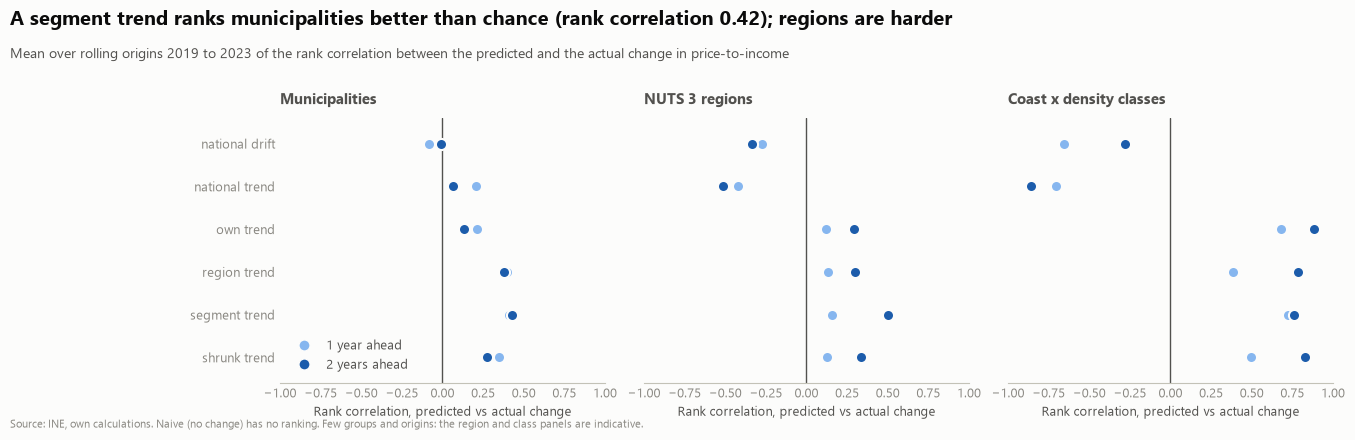

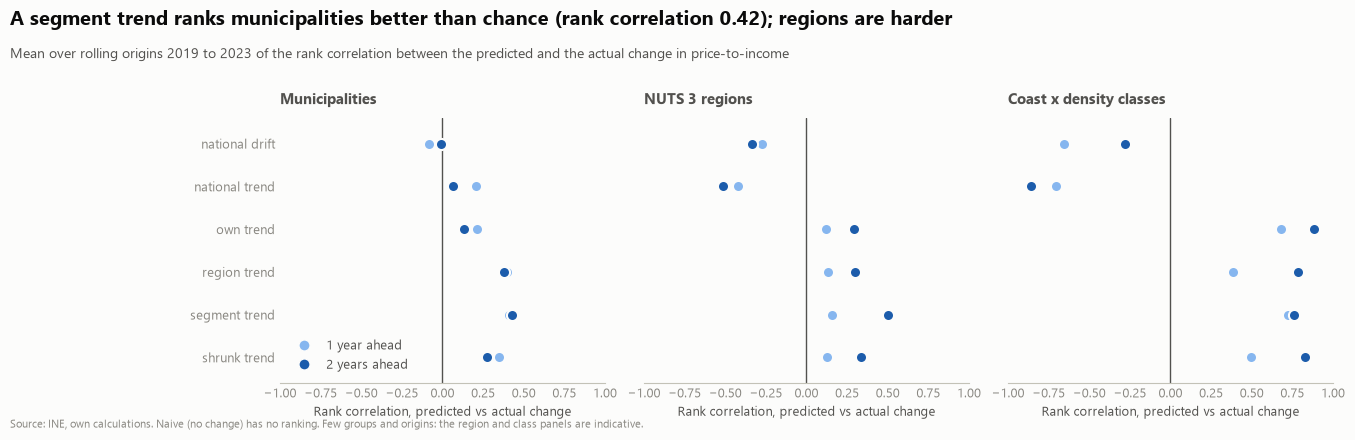

In [5]:
fig = charts.regional_skill(
    {
        "Municipalities": level_acc["municipality"],
        "NUTS 3 regions": level_acc["NUTS 3 region"],
        "Coast x density classes": level_acc["coast x density class"],
    }
)
style.save_fig(fig, "p4", "regional_skill")
fig

## Step 2 — The outlook, relative to the median municipality
Fitted on all data to 2024. The relative change of a group is its median forecast change minus the median
municipality's, with an 80% interval from the relative errors of the backtest (aggregated the same way).

In [6]:
HORIZON = 2
END_YEAR = int(y.columns.max()) + HORIZON
out = R.outlook(y, groups, chosen)
out["change"] = out["forecast"] - out["last"]
national = out[out["h"] == HORIZON]["change"].median()
mu = out[out["h"] == HORIZON].copy()
rel_muni = R.relative_errors(bt, chosen)
qm = rel_muni[rel_muni["h"] == HORIZON]["error"].quantile([0.1, 0.9])
mu["relative"] = 100 * (mu["change"] - national)
mu["relative_lo80"] = mu["relative"] + 100 * qm[0.1]
mu["relative_hi80"] = mu["relative"] + 100 * qm[0.9]
mu["pti_last"] = np.exp(mu["last"])
mu["pti_forecast"] = np.exp(mu["forecast"])
mu["change_pct"] = 100 * np.expm1(mu["change"])
cols = ["muni_code", "muni_name", "district", "region", "segment", "pti_last", "pti_forecast"]
cols += ["change_pct", "relative", "relative_lo80", "relative_hi80"]
munis = mu[cols].sort_values("relative", ascending=False)
style.save_table(munis.round(3), "p4", "regional_outlook_municipalities")
print(
    f"median municipality: {100 * np.expm1(national):+.1f}% in {HORIZON} years (trend of 2016-2024)"
)
munis.head(10).round(1)

median municipality: +7.8% in 2 years (trend of 2016-2024)


,muni_code,muni_name,district,region,segment,pti_last,pti_forecast,change_pct,relative,relative_lo80,relative_hi80
521,1801,Armamar,Viseu,Douro,inland / rural,2.4,4.8,97.0,60.3,40.1,74.7
524,1804,Cinfães,Viseu,Tâmega e Sousa,inland / rural,4.0,6.5,63.4,41.6,21.4,56.0
513,1707,Murça,Vila Real,Douro,inland / rural,3.7,5.9,57.5,37.9,17.7,52.3
514,1708,Peso da Régua,Vila Real,Douro,inland / intermediate,6.5,10.1,54.8,36.2,16.0,50.6
457,1313,Póvoa de Varzim,Porto,Área Metropolitana do Porto,coast / urban,20.2,29.0,43.5,28.6,8.4,43.0
420,1106,Lisboa,Lisboa,Grande Lisboa,coast / urban,24.8,35.4,42.8,28.1,7.9,42.5
281,0110,Ílhavo,Aveiro,Região de Aveiro,coast / urban,16.0,22.6,41.1,26.9,6.7,41.4
538,1819,Tabuaço,Viseu,Douro,inland / rural,3.9,5.5,39.6,25.8,5.6,40.3
460,1316,Vila do Conde,Porto,Área Metropolitana do Porto,coast / urban,18.8,26.2,39.5,25.8,5.6,40.2
316,0314,Vizela,Braga,Ave,inland / urban,11.2,15.2,36.2,23.4,3.2,37.8


In [7]:
by_region = R.outlook_summary(
    out, "region", HORIZON, R.relative_errors(bt, chosen, groups, "region")
)
by_segment = R.outlook_summary(
    out, "segment", HORIZON, R.relative_errors(bt, chosen, groups, "segment")
)
style.save_table(by_region.round(3), "p4", "regional_outlook_regions")
style.save_table(by_segment.round(3), "p4", "regional_outlook_classes")
by_segment.round(2)

,segment,municipalities_n,change,share_rising,change_pct,relative,relative_lo80,relative_hi80
0,coast / urban,17,0.22,1.00,24.81,14.64,7.38,17.64
1,coast / rural,17,0.17,1.00,18.42,9.39,2.13,12.39
2,coast / intermediate,32,0.12,1.00,12.87,4.59,-2.67,7.58
3,inland / urban,15,0.11,0.93,11.83,3.66,-3.60,6.66
4,inland / intermediate,42,0.08,0.69,8.27,0.43,-6.83,3.42
5,inland / rural,149,0.02,0.55,2.03,-5.51,-12.77,-2.51


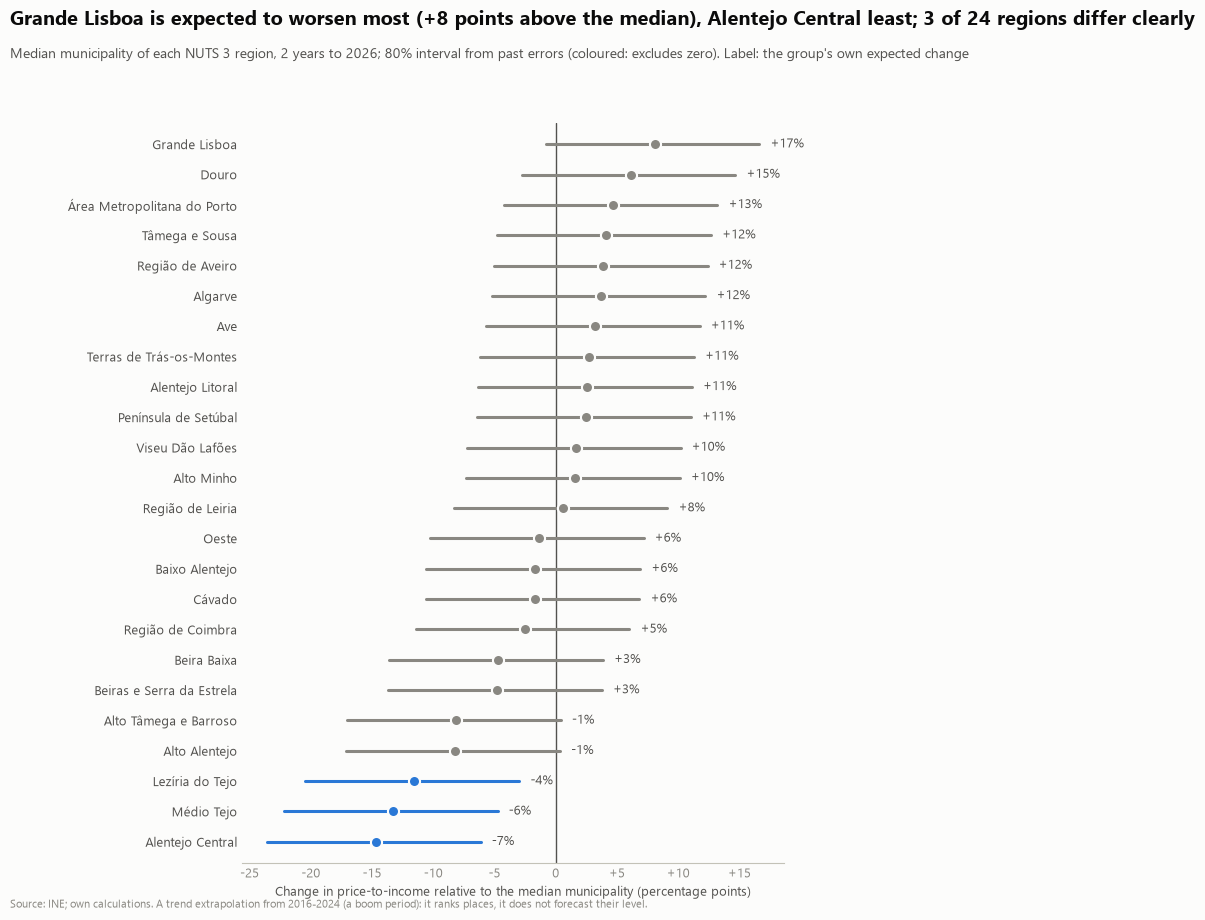

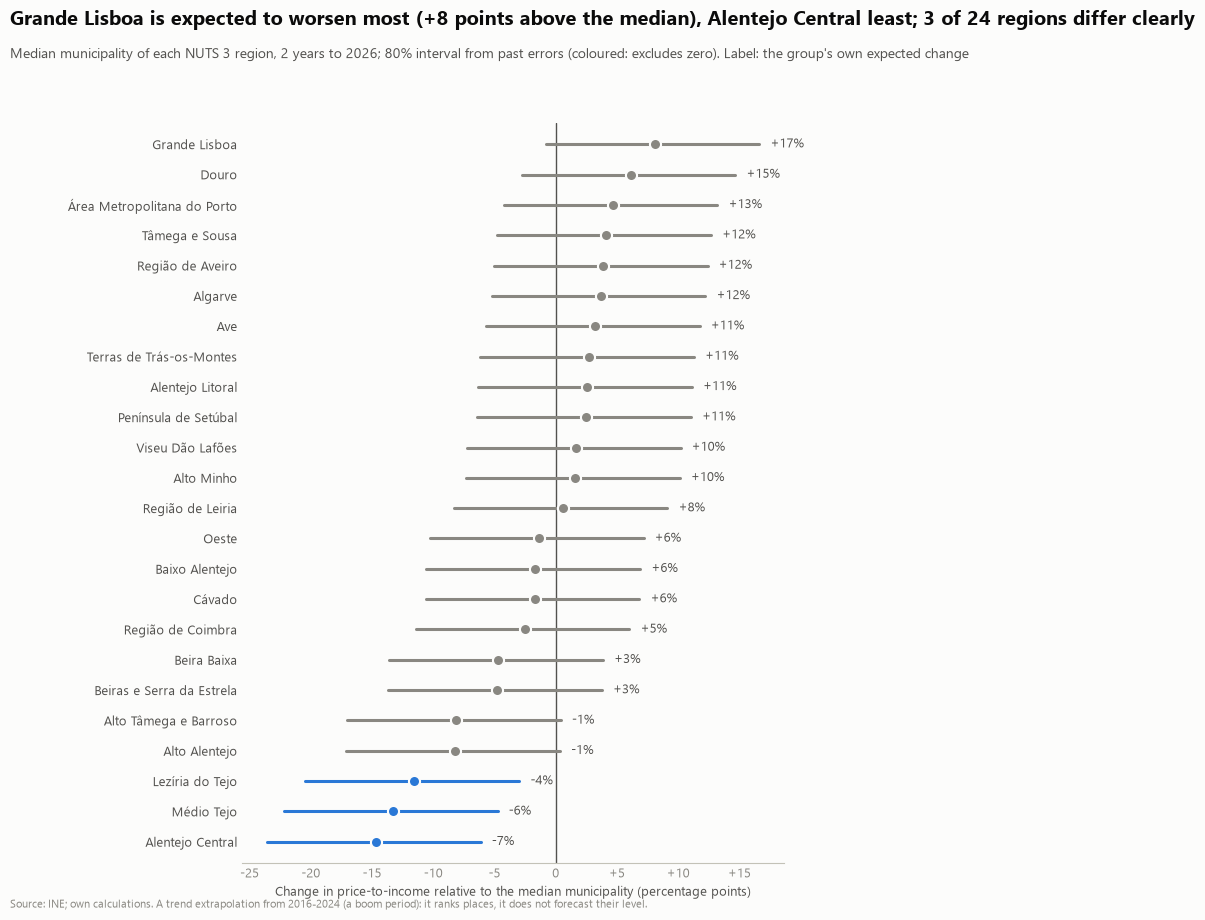

In [8]:
fig = charts.outlook_ranking(
    by_region.rename(columns={"region": "label"}), "NUTS 3 region", "regions", HORIZON, END_YEAR
)
style.save_fig(fig, "p4", "regional_outlook_regions")
fig

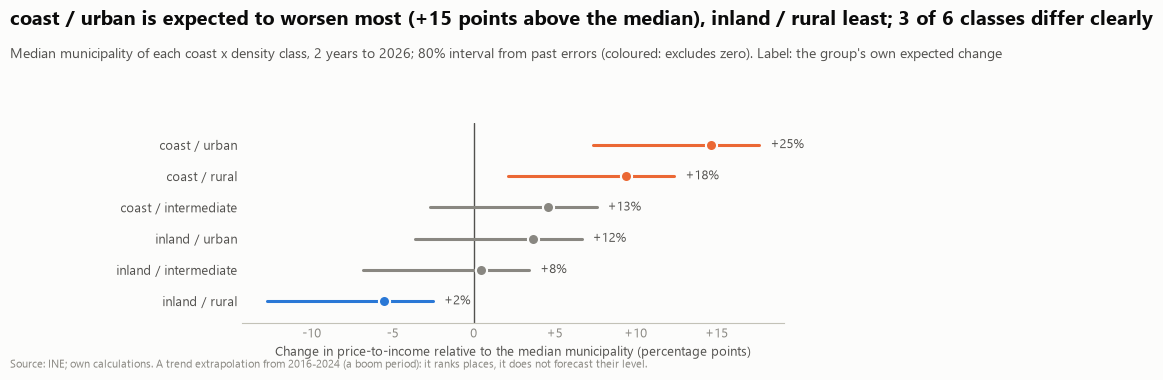

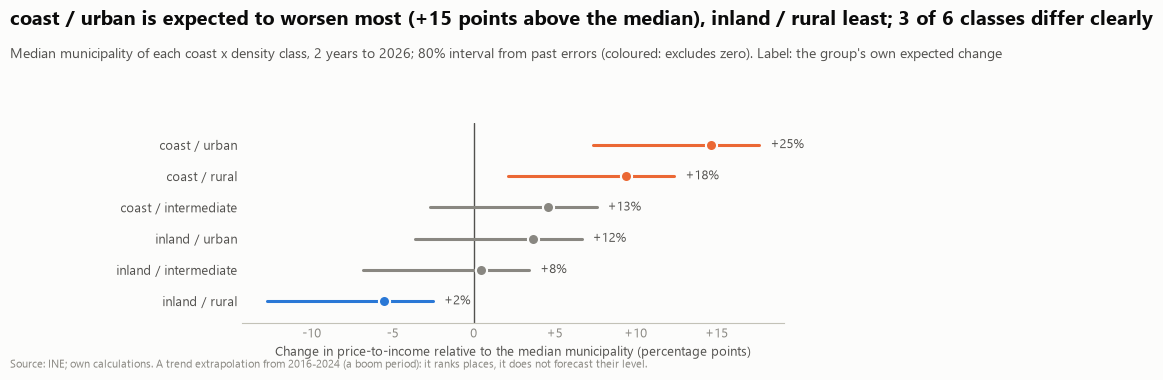

In [9]:
fig = charts.outlook_ranking(
    by_segment.rename(columns={"segment": "label"}),
    "coast x density class",
    "classes",
    HORIZON,
    END_YEAR,
)
style.save_fig(fig, "p4", "regional_outlook_classes")
fig

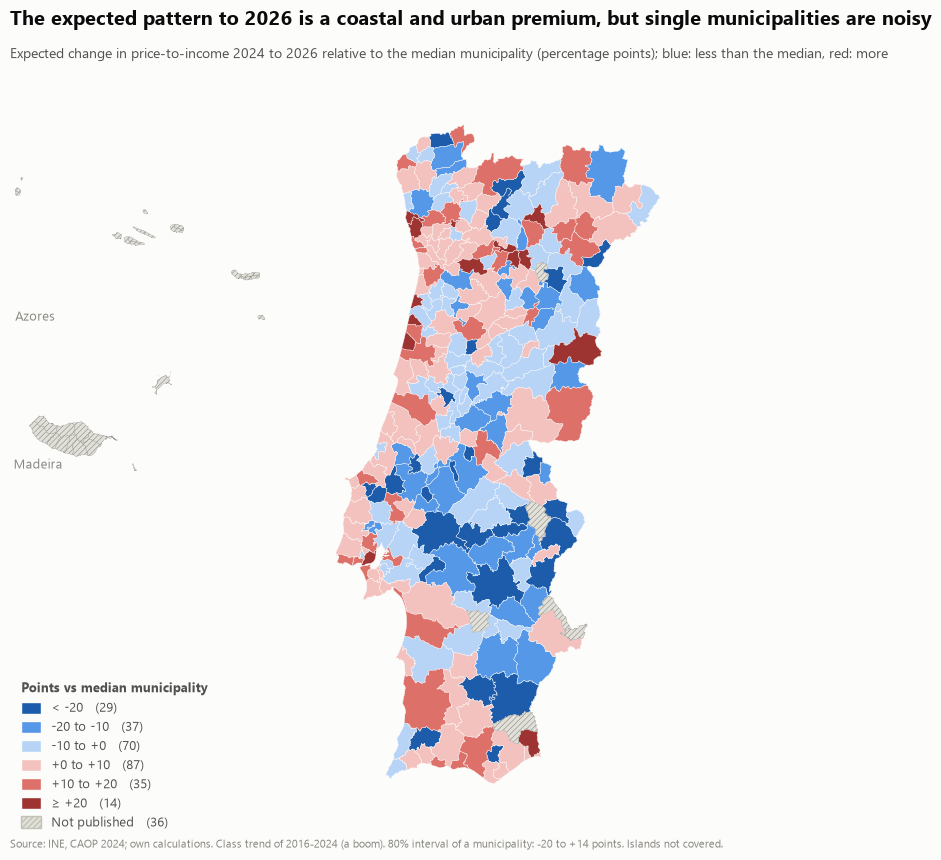

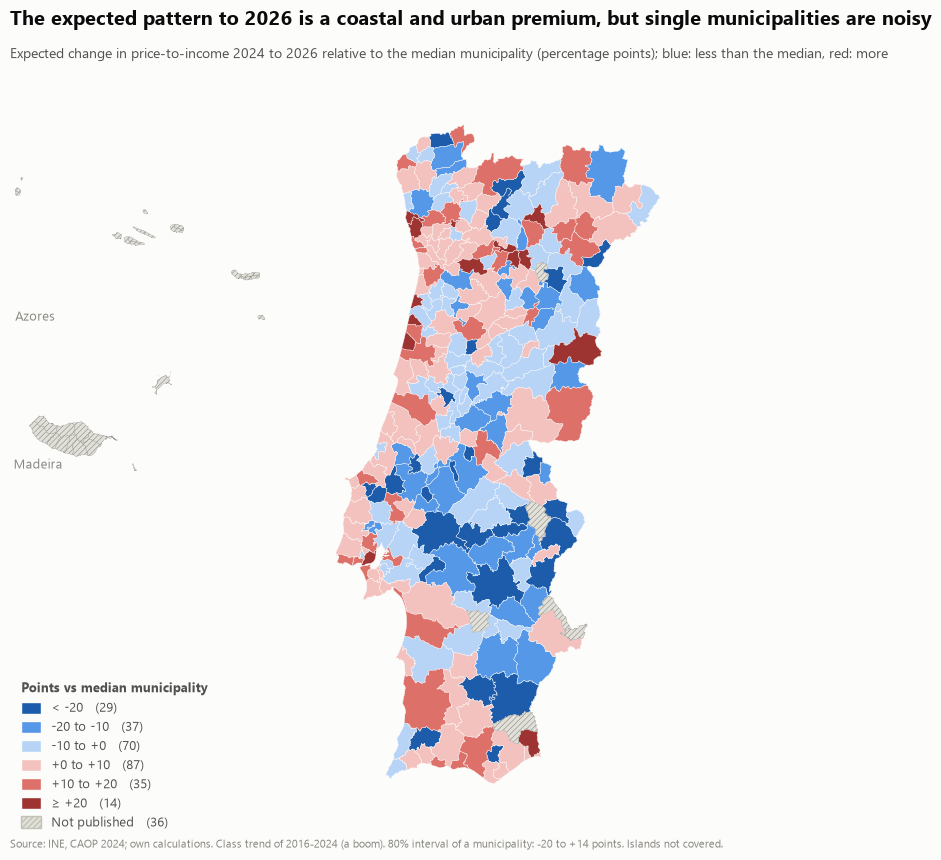

In [10]:
geometry = maps.municipality_geometry()
values = munis.set_index("muni_code")["relative"]
fig = maps.choropleth(
    values, geometry, [-20, -10, 0, 10, 20], style.diverging_ramp(3),
    f"The expected pattern to {END_YEAR} is a coastal and urban premium, but single municipalities are noisy",
    f"Expected change in price-to-income {y.columns.max()} to {END_YEAR} relative to the median municipality (percentage points); blue: less than the median, red: more",
    "Source: INE, CAOP 2024; own calculations. Class trend of 2016-2024 (a boom). 80% interval of a municipality: -20 to +14 points. Islands not covered.",
    "Points vs median municipality", fmt="{:+g}",
)  # fmt: skip
style.save_fig(fig, "p4", "regional_outlook_map")
fig

## Step 3 — Checks
1. **Does the choice of method change the ranking?** Rank correlation of the municipal outlooks between methods.
2. **Does the result depend on the 2023 origin** (the only origin whose target year is 2024, after the jump)?
3. **Is the national level consistent with the simulator?**

In [11]:
names = ("own_trend", "region_trend", "segment_trend", "shrunk_trend")
outs = {m: R.outlook(y, groups, m, (HORIZON,)).set_index("muni_code") for m in names}
chg = pd.DataFrame({m: o["forecast"] - o["last"] for m, o in outs.items()})
print("rank correlation of the predicted change between methods")
chg.corr(method="spearman").round(2)

rank correlation of the predicted change between methods


,own_trend,region_trend,segment_trend,shrunk_trend
own_trend,1.00,0.38,0.35,0.78
region_trend,0.38,1.00,0.55,0.79
segment_trend,0.35,0.55,1.00,0.49
shrunk_trend,0.78,0.79,0.49,1.00


In [12]:
alt_bt = R.backtest(y, groups, origins=(2019, 2020, 2021, 2022))
alt = R.accuracy(alt_bt)
alt_naive = alt[alt["method"] == "naive"].set_index("h")["rmse"]
alt["rmse_vs_naive"] = alt["rmse"] / alt["h"].map(alt_naive)
print("selected without the 2023 origin:", R.select_method(alt))
alt[alt["method"].isin(["naive", "region_trend", "segment_trend", "shrunk_trend"])].round(3)

selected without the 2023 origin: segment_trend


,method,h,n,rmse,mae,bias,spearman,top_precision,rmse_vs_naive
0,naive,1,265.50,0.154,0.112,-0.026,NaN,0.170,1.000
1,naive,2,269.25,0.170,0.129,-0.037,NaN,0.140,1.000
8,region_trend,1,265.50,0.143,0.103,-0.005,0.367,0.430,0.928
9,region_trend,2,269.25,0.163,0.119,0.009,0.378,0.391,0.959
10,segment_trend,1,265.50,0.141,0.100,-0.006,0.406,0.436,0.914
11,segment_trend,2,269.25,0.156,0.113,0.007,0.430,0.400,0.920
12,shrunk_trend,1,265.50,0.158,0.105,-0.004,0.328,0.396,1.029
13,shrunk_trend,2,269.25,0.194,0.126,0.011,0.271,0.340,1.142


In [13]:
paths = pd.read_csv(TABLES / "p4" / "scenario_paths.csv")
is_end = (paths["scenario"] == "baseline") & (paths["metric"] == "pti_years")
sim = paths[is_end & (paths["year"] == END_YEAR)]["p50"].iloc[0]
base = panel[panel["year"] == y.columns.max()]["pti_years"].median()
print(
    f"simulator baseline: {100 * (sim / base - 1):+.0f}% {y.columns.max()} to {END_YEAR} "
    "(pinned to the national forecast, which includes 2025's price rise)"
)
print(
    f"municipal trend of 2016-2024: {100 * np.expm1(national):+.0f}%: the level is the simulator's job"
)

simulator baseline: +26% 2024 to 2026 (pinned to the national forecast, which includes 2025's price rise)
municipal trend of 2016-2024: +8%: the level is the simulator's job


## What this says
See `reports/p4_forecast.md` (regional outlook) for the reading and the limits. Tables: `reports/tables/p4/regional_*.csv`.